# 🕷️ PeterPark – Phân tích log tấn công SSH
**Tác giả:** Nguyễn Văn Tùng (PeterPark) · Dự án Data Analytics × An ninh mạng

## 1. Bối cảnh & câu hỏi
Mọi máy chủ mở cổng SSH ra Internet đều bị bot dò quét và thử đăng nhập liên tục. Dự án này phân tích **file `auth.log` thật** của một máy chủ Linux trên AWS (công khai bởi SecRepo, giấy phép CC BY 4.0) để trả lời:
1. Có bao nhiêu sự kiện tấn công, gồm những loại nào?
2. IP / dải mạng nào tấn công nhiều nhất?
3. Tấn công diễn ra theo ngày và theo giờ như thế nào?
4. Kẻ tấn công thử những username nào?
5. Độ lớn của brute-force: phần lớn IP thử ít hay một số ít IP thử rất nhiều?
6. Từ đó nên phòng thủ thế nào?
7. *(v2)* Tấn công diễn ra theo đợt ra sao, bot hay người, đến từ đâu, nhắm loại tài khoản nào? → mục 5, 6, 8 + dashboard Power BI.

> **Nguồn dữ liệu:** https://www.secrepo.com/auth.log/auth.log.gz – SecRepo.com, Mike Sconzo, CC BY 4.0. Dùng toàn bộ file, không lấy mẫu.
> **Giới hạn:** log không có năm, không có quốc gia, và server này không ghi dòng `Failed password` (nên không có mật khẩu bị thử). Quốc gia sẽ cần tra GeoIP – nằm ngoài phạm vi bản này.

In [1]:
import re, gzip, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
RED, BLUE, LIGHT, INK = '#B11313', '#0B1E4A', '#E8EEF9', '#222222'
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,
    'axes.titleweight':'bold','axes.titlesize':13,'axes.edgecolor':BLUE,'axes.labelcolor':BLUE,
    'xtick.color':INK,'ytick.color':INK,'font.size':10})
CHARTS = Path('charts'); CHARTS.mkdir(exist_ok=True)
pd.set_option('display.width', 140)

## 2. Đọc & làm sạch log bằng regex
Mỗi dòng có dạng `Tháng Ngày HH:MM:SS host chương_trình[pid]: nội dung`. Ta tách phần đầu rồi phân loại nội dung bằng một danh sách regex.

In [2]:
with gzip.open('data/auth.log.gz', 'rt', encoding='utf-8', errors='replace') as f:
    lines = f.read().splitlines()
print('Số dòng log:', len(lines)); print(lines[3])

Số dòng log: 86839
Nov 30 07:07:14 ip-172-31-27-153 sshd[22116]: Connection closed by 122.225.103.87 [preauth]


In [3]:
HEAD = re.compile(r'^(?P<mon>\w{3})\s+(?P<day>\d+) (?P<time>[\d:]{8}) (?P<host>\S+) (?P<program>[\w\-\.]+)(?:\[(?P<pid>\d+)\])?: (?P<msg>.*)$')
IP = r'(?P<ip>\d{1,3}(?:\.\d{1,3}){3})'
RULES = [
  ('invalid_user',           re.compile(r'^Invalid user (?P<user>.*?) from ' + IP)),
  ('disconnect_preauth',     re.compile(r'^Received disconnect from ' + IP + r'.*\[preauth\]')),
  ('reverse_mapping_failed', re.compile(r'^reverse mapping checking getaddrinfo .*\[' + IP + r'\] failed')),
  ('too_many_auth_failures', re.compile(r'^Disconnecting: Too many authentication failures for (?:invalid user )?(?P<user>\S+)')),
  ('no_identification',      re.compile(r'^Did not receive identification string from ' + IP)),
  ('connection_closed',      re.compile(r'^Connection closed by ' + IP)),
  ('connection_reset',       re.compile(r'Connection reset by peer')),
  ('userauth_request_invalid', re.compile(r'^input_userauth_request: invalid user (?P<user>\S*)')),
  ('cron_session',           re.compile(r'^pam_unix\(cron:session\)')),
]
rows, bad = [], 0
for ln in lines:
    m = HEAD.match(ln)
    if not m: bad += 1; continue
    d = m.groupdict(); et, user, ip = 'other', None, None
    for name, rx in RULES:
        r = rx.search(d['msg'])
        if r:
            et = name; g = r.groupdict(); user = g.get('user'); ip = g.get('ip'); break
    if ip is None:
        r = re.search(IP, d['msg']); ip = r.group('ip') if r else None
    rows.append(dict(mon=d['mon'], day=int(d['day']), time=d['time'], program=d['program'],
                     pid=d['pid'], event_type=et, ip=ip, username=user, msg=d['msg']))
df = pd.DataFrame(rows)
print('Không parse được:', bad, 'dòng'); df.head()

Không parse được: 0 dòng


,mon,day,time,program,pid,event_type,ip,username,msg
0,Nov,30,06:39:00,CRON,21882,cron_session,NaN,NaN,pam_unix(cron:session): session closed for use...
1,Nov,30,06:47:01,CRON,22087,cron_session,NaN,NaN,pam_unix(cron:session): session opened for use...
2,Nov,30,06:47:03,CRON,22087,cron_session,NaN,NaN,pam_unix(cron:session): session closed for use...
3,Nov,30,07:07:14,sshd,22116,connection_closed,122.225.103.87,NaN,Connection closed by 122.225.103.87 [preauth]
4,Nov,30,07:07:35,sshd,22118,connection_closed,122.225.103.87,NaN,Connection closed by 122.225.103.87 [preauth]


Log không ghi năm. Dữ liệu chạy từ 30/11 đến 31/12, nên ta gán **một năm giả định (2000)** chỉ để sắp xếp thời gian – không dùng để suy ra thứ trong tuần.

In [4]:
MON = {'Nov':11,'Dec':12}
assert set(df.mon) <= set(MON), set(df.mon)
df['ts'] = pd.to_datetime('2000-' + df.mon.map(MON).astype(str) + '-' + df.day.astype(str) + ' ' + df.time)
df['subnet24'] = df.ip.str.rsplit('.', n=1).str[0] + '.0/24'
df = df.drop(columns=['mon','day','time'])
print('Từ', df.ts.min(), 'đến', df.ts.max(), '| số dòng sạch:', len(df), '| trùng lặp:', df.duplicated().sum())
df.event_type.value_counts()

Từ 2000-11-30 06:39:00 đến 2000-12-31 22:27:48 | số dòng sạch: 86839 | trùng lặp: 0


event_type
disconnect_preauth          46810
invalid_user                12250
userauth_request_invalid    12250
reverse_mapping_failed       5226
too_many_auth_failures       2575
connection_reset             2411
connection_closed            1974
cron_session                 1593
no_identification             969
other                         781
Name: count, dtype: int64

## 3. Đưa vào SQLite & truy vấn SQL
Toàn bộ câu SQL nằm trong thư mục `sql/` để có thể chạy lại bằng bất kỳ công cụ SQLite nào.

In [5]:
con = sqlite3.connect('data/auth_log.db')
df.assign(ts=df.ts.dt.strftime('%Y-%m-%d %H:%M:%S')).to_sql('logs', con, if_exists='replace', index=False)
def q(file):
    sql = Path('sql', file).read_text(encoding='utf-8'); print(sql.strip().splitlines()[0]); return pd.read_sql(sql, con)
q('01_tong_quan.sql')

-- Tổng quan: số dòng log, số sự kiện theo loại


,event_type,so_su_kien
0,disconnect_preauth,46810
1,userauth_request_invalid,12250
2,invalid_user,12250
3,reverse_mapping_failed,5226
4,too_many_auth_failures,2575
5,connection_reset,2411
6,connection_closed,1974
7,cron_session,1593
8,no_identification,969
9,other,781


## 4. Phân tích
### 4.1 Loại sự kiện

-- Tổng quan: số dòng log, số sự kiện theo loại


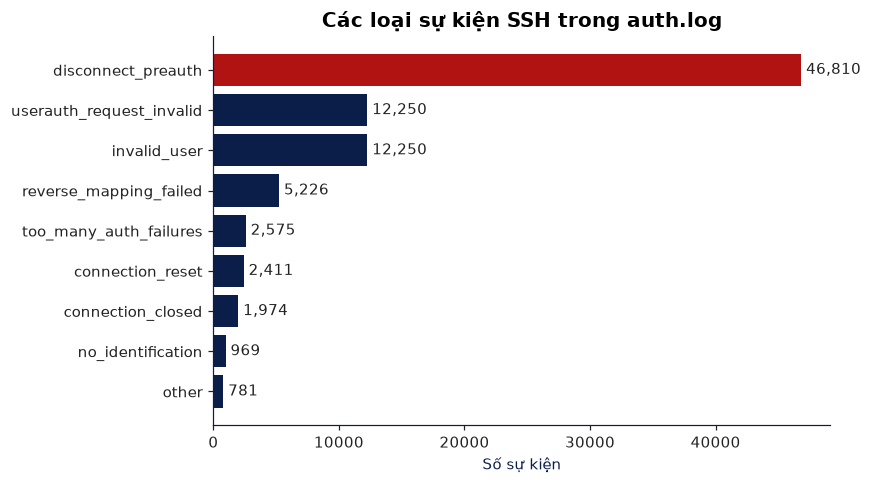

In [6]:
t = q('01_tong_quan.sql').query("event_type!='cron_session'").sort_values('so_su_kien')
fig, ax = plt.subplots(figsize=(8,4.5))
ax.barh(t.event_type, t.so_su_kien, color=[RED if i==len(t)-1 else BLUE for i in range(len(t))])
for y,v in enumerate(t.so_su_kien): ax.text(v, y, f' {v:,}', va='center', color=INK)
ax.set_title('Các loại sự kiện SSH trong auth.log'); ax.set_xlabel('Số sự kiện')
plt.tight_layout(); plt.savefig(CHARTS/'01_loai_su_kien.png'); plt.show()

### 4.2 Top IP & dải mạng tấn công

In [7]:
top = q('02_top_ip.sql'); ssh = df[df.program=='sshd']
print('Tổng sự kiện sshd:', len(ssh), '| số IP khác nhau:', ssh.ip.nunique())
print(f"Top 10 IP chiếm {top.so_su_kien.sum()/ssh.ip.notna().sum():.1%} sự kiện có IP")
top

-- Top 10 IP có nhiều sự kiện tấn công SSH nhất
Tổng sự kiện sshd: 85246 | số IP khác nhau: 1843
Top 10 IP chiếm 56.5% sự kiện có IP


,ip,so_su_kien,so_ngay_hoat_dong,lan_dau,lan_cuoi
0,61.197.203.243,11261,1,2000-12-06 08:23:28,2000-12-06 13:27:29
1,220.99.93.50,10752,2,2000-12-02 05:19:56,2000-12-03 02:56:36
2,218.25.17.234,5616,1,2000-12-02 12:23:36,2000-12-02 16:02:54
3,188.87.35.25,3676,1,2000-12-14 02:57:00,2000-12-14 03:42:57
4,78.129.223.28,1804,1,2000-12-26 02:01:10,2000-12-26 02:20:51
5,67.205.20.23,1804,1,2000-12-01 08:31:02,2000-12-01 08:50:16
6,222.161.209.92,1493,7,2000-12-11 14:56:47,2000-12-31 01:33:14
7,173.192.158.3,748,1,2000-12-02 04:12:40,2000-12-02 04:17:19
8,218.75.153.170,733,2,2000-11-30 14:03:41,2000-12-01 02:28:32
9,108.63.28.45,605,3,2000-12-23 20:46:15,2000-12-29 20:08:30


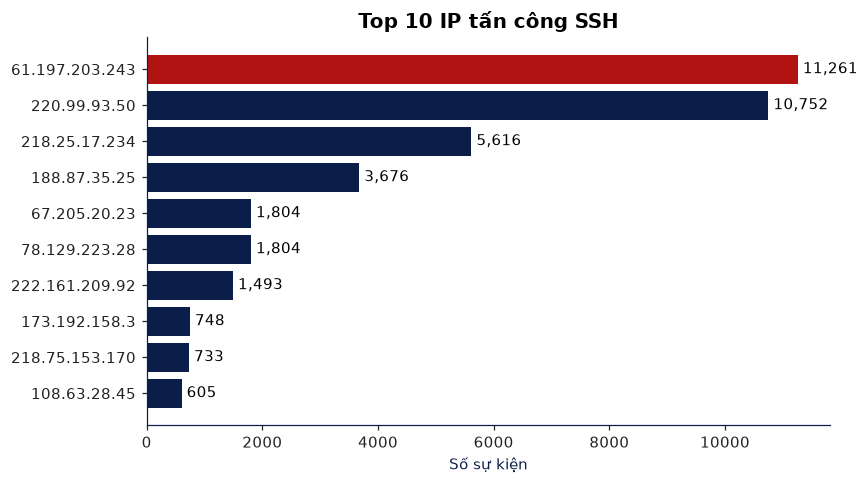

In [8]:
t = top.sort_values('so_su_kien')
fig, ax = plt.subplots(figsize=(8,4.5))
ax.barh(t.ip, t.so_su_kien, color=BLUE); ax.barh(t.ip.iloc[-1:], t.so_su_kien.iloc[-1:], color=RED)
for y,v in enumerate(t.so_su_kien): ax.text(v, y, f' {v:,}', va='center')
ax.set_title('Top 10 IP tấn công SSH'); ax.set_xlabel('Số sự kiện')
plt.tight_layout(); plt.savefig(CHARTS/'02_top_ip.png'); plt.show()

In [9]:
q('07_top_subnet.sql')

-- Top 10 dải mạng /24 (cột subnet24 được tính sẵn khi nạp dữ liệu)


,subnet24,so_su_kien,so_ip
0,61.197.203.0/24,11261,1
1,220.99.93.0/24,10752,1
2,218.25.17.0/24,5616,1
3,188.87.35.0/24,3676,1
4,78.129.223.0/24,1804,1
5,67.205.20.0/24,1804,1
6,222.161.209.0/24,1493,1
7,173.192.158.0/24,748,1
8,218.75.153.0/24,733,1
9,108.63.28.0/24,607,2


### 4.3 Theo thời gian

-- Số sự kiện SSH theo ngày
Ngày cao điểm: 02/12 17548 sự kiện | trung vị/ngày: 1848.0


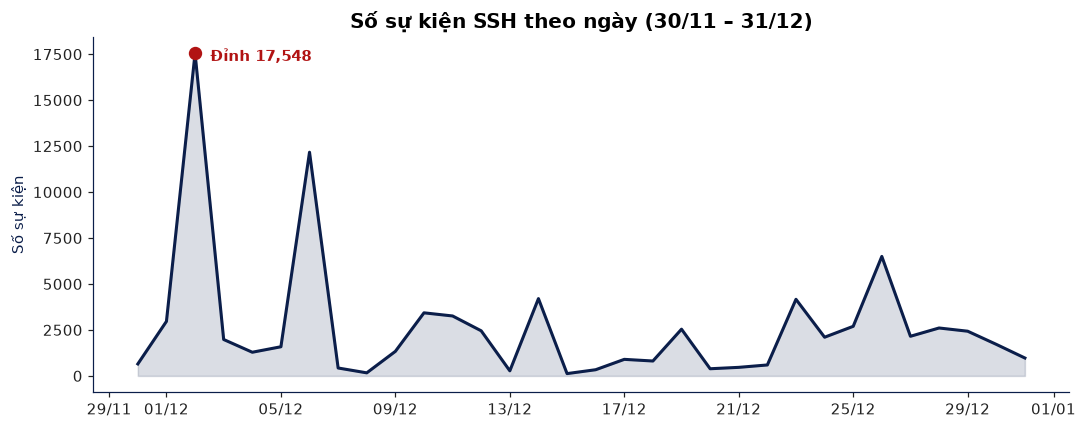

In [10]:
d = q('03_theo_ngay.sql'); d['ngay'] = pd.to_datetime(d.ngay)
print('Ngày cao điểm:', d.loc[d.so_su_kien.idxmax(),'ngay'].strftime('%d/%m'), d.so_su_kien.max(), 'sự kiện | trung vị/ngày:', d.so_su_kien.median())
fig, ax = plt.subplots(figsize=(10,4))
ax.fill_between(d.ngay, d.so_su_kien, color=BLUE, alpha=.15); ax.plot(d.ngay, d.so_su_kien, color=BLUE, lw=2)
pk = d.loc[d.so_su_kien.idxmax()]; ax.scatter([pk.ngay],[pk.so_su_kien], color=RED, s=60, zorder=3)
ax.annotate(f"Đỉnh {pk.so_su_kien:,}", (pk.ngay, pk.so_su_kien), xytext=(10,-5), textcoords='offset points', color=RED, fontweight='bold')
import matplotlib.dates as mdates; ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
ax.set_title('Số sự kiện SSH theo ngày (30/11 – 31/12)'); ax.set_ylabel('Số sự kiện')
plt.tight_layout(); plt.savefig(CHARTS/'03_theo_ngay.png'); plt.show()

-- Số sự kiện SSH theo giờ trong ngày (giờ của server)


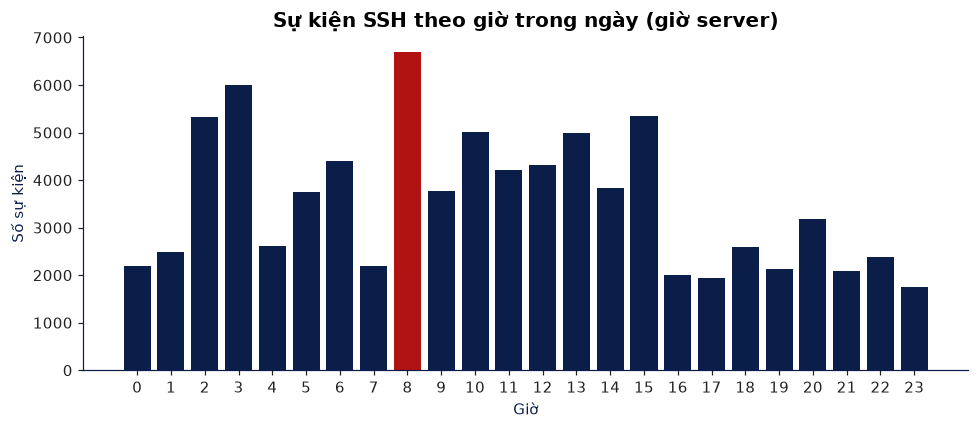

Giờ cao điểm: 8 | giờ thấp nhất: 23


In [11]:
h = q('04_theo_gio.sql').set_index('gio').reindex(range(24), fill_value=0).reset_index()
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(h.gio, h.so_su_kien, color=[RED if v==h.so_su_kien.max() else BLUE for v in h.so_su_kien])
ax.set_xticks(range(24)); ax.set_title('Sự kiện SSH theo giờ trong ngày (giờ server)'); ax.set_xlabel('Giờ'); ax.set_ylabel('Số sự kiện')
plt.tight_layout(); plt.savefig(CHARTS/'04_theo_gio.png'); plt.show()
print('Giờ cao điểm:', int(h.loc[h.so_su_kien.idxmax(),'gio']), '| giờ thấp nhất:', int(h.loc[h.so_su_kien.idxmin(),'gio']))

### 4.4 Username bị thử

-- Top 15 username không tồn tại bị kẻ tấn công thử
Số lần thử user không tồn tại: 12250 | số username khác nhau: 542


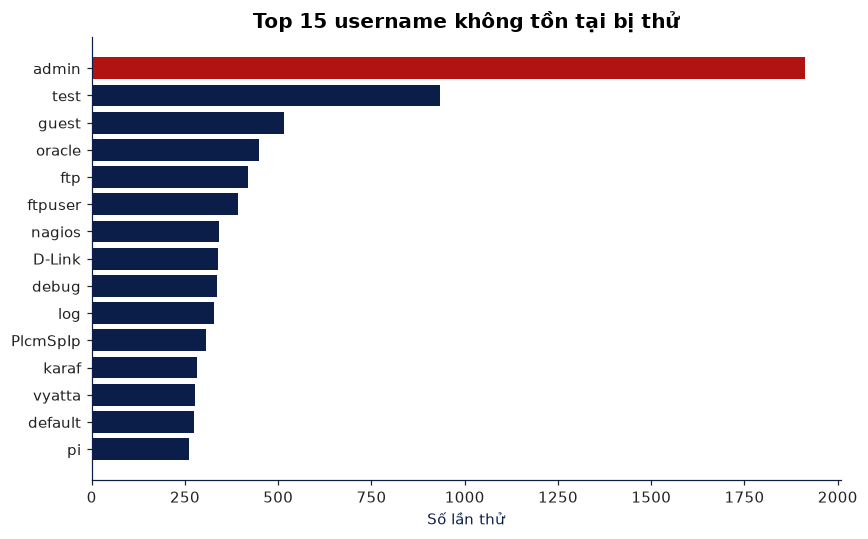

,username,so_lan_thu,so_ip
0,admin,1912,784
1,test,933,179
2,guest,515,226
3,oracle,449,177
4,ftp,418,158
5,ftpuser,392,320
6,nagios,340,16
7,D-Link,339,280
8,debug,335,267
9,log,327,260


In [12]:
u = q('05_top_username.sql')
print('Số lần thử user không tồn tại:', (df.event_type=='invalid_user').sum(), '| số username khác nhau:', df.loc[df.event_type=='invalid_user','username'].nunique())
t = u.sort_values('so_lan_thu')
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(t.username, t.so_lan_thu, color=BLUE); ax.barh(t.username.iloc[-1:], t.so_lan_thu.iloc[-1:], color=RED)
ax.set_title('Top 15 username không tồn tại bị thử'); ax.set_xlabel('Số lần thử')
plt.tight_layout(); plt.savefig(CHARTS/'05_top_username.png'); plt.show(); u

In [13]:
q('08_root_too_many.sql')

-- Tài khoản bị khóa phiên do "Too many authentication failures"


,username,so_lan
0,root,2575


### 4.5 Độ lớn brute-force

-- Phân nhóm IP theo độ lớn brute-force (số lần thử user không tồn tại)
       nhom  so_ip  tong_lan_thu  ty_le_ip  ty_le_lan_thu
0         1    328           328  0.260317       0.026776
1      2-10    711          2424  0.564286       0.197878
2    11-100    208          5767  0.165079       0.470776
3  101-1000     13          3731  0.010317       0.304571


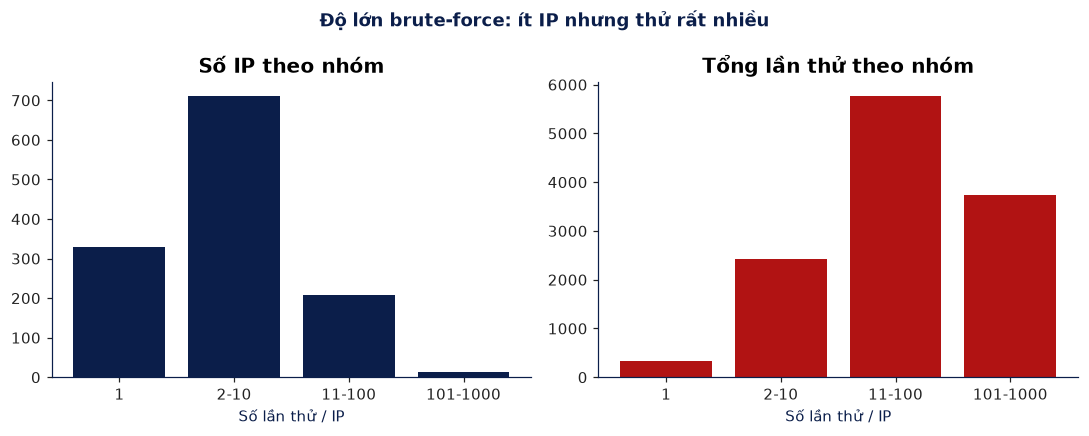

In [14]:
b = q('06_do_lon_brute_force.sql'); b['ty_le_ip'] = b.so_ip/b.so_ip.sum(); b['ty_le_lan_thu'] = b.tong_lan_thu/b.tong_lan_thu.sum(); print(b)
fig, ax = plt.subplots(1,2, figsize=(10,4))
ax[0].bar(b.nhom, b.so_ip, color=BLUE); ax[0].set_title('Số IP theo nhóm'); ax[0].set_xlabel('Số lần thử / IP')
ax[1].bar(b.nhom, b.tong_lan_thu, color=RED); ax[1].set_title('Tổng lần thử theo nhóm'); ax[1].set_xlabel('Số lần thử / IP')
fig.suptitle('Độ lớn brute-force: ít IP nhưng thử rất nhiều', fontweight='bold', color=BLUE)
plt.tight_layout(); plt.savefig(CHARTS/'06_do_lon_brute_force.png'); plt.show()

## 5. Phân tích chuyên sâu (v2)
Phần này đào sâu hơn để tìm **insight**: tấn công rơi vào khung giờ nào, mỗi IP tấn công theo "đợt" ra sao, là bot hay người, đến từ quốc gia/nhà mạng nào, và thử những loại tài khoản gì.

**Quy ước:** *sự kiện tấn công* = mọi dòng của `sshd` có địa chỉ IP (bỏ `cron`).

In [15]:
import numpy as np
att = df[(df.program=='sshd') & df.ip.notna()].sort_values('ts').copy()
att['ngay'] = att.ts.dt.normalize(); att['gio'] = att.ts.dt.hour
print('Sự kiện tấn công:', f'{len(att):,}', '| IP:', att.ip.nunique())

Sự kiện tấn công: 68,080 | IP: 1843


### 5.1 Bản đồ nhiệt Ngày × Giờ
Mỗi ô là số sự kiện trong 1 giờ của 1 ngày. Ô càng đỏ càng nhiều. Giúp thấy tấn công là **từng đợt bùng nổ** hay đều đặn.

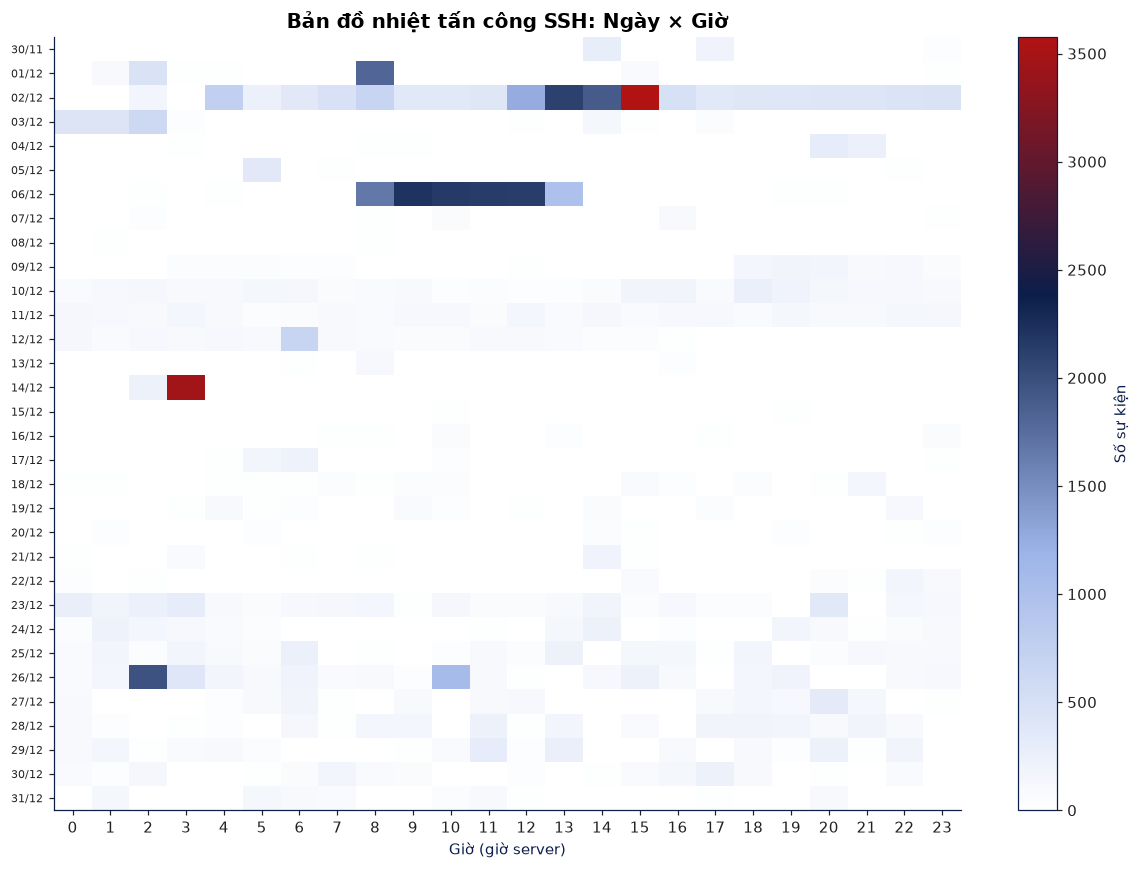

Số ô giờ có tấn công: 615 / 768
Top 10 giờ (trong 768 giờ) chiếm 34.4% sự kiện
Giờ nặng nhất: 02/12 15h - 3576 sự kiện


In [16]:
from matplotlib.colors import LinearSegmentedColormap
hm = att.pivot_table(index='ngay', columns='gio', values='ip', aggfunc='size', fill_value=0).reindex(columns=range(24), fill_value=0)
cmap = LinearSegmentedColormap.from_list('pp', ['#FFFFFF', '#9DB4E8', BLUE, RED])
fig, ax = plt.subplots(figsize=(11,8))
im = ax.imshow(hm.values, aspect='auto', cmap=cmap)
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index.strftime('%d/%m'), fontsize=7)
ax.set_xticks(range(24)); ax.set_xlabel('Giờ (giờ server)'); ax.set_title('Bản đồ nhiệt tấn công SSH: Ngày × Giờ')
fig.colorbar(im, ax=ax, label='Số sự kiện'); plt.tight_layout(); plt.savefig(CHARTS/'07_heatmap_ngay_gio.png'); plt.show()
cells = hm.stack()
print('Số ô giờ có tấn công:', (cells>0).sum(), '/', cells.size)
print(f'Top 10 giờ (trong {cells.size} giờ) chiếm {cells.nlargest(10).sum()/cells.sum():.1%} sự kiện')
print('Giờ nặng nhất:', cells.idxmax()[0].strftime('%d/%m'), f'{cells.idxmax()[1]}h', '-', cells.max(), 'sự kiện')

### 5.2 "Đợt tấn công" (session) của từng IP
Nếu một IP im lặng **hơn 30 phút** rồi quay lại thì tính là **đợt mới**. Với mỗi đợt ta đo thời lượng, số sự kiện và tốc độ.

In [17]:
att['gap_s'] = att.groupby('ip').ts.diff().dt.total_seconds()
att['dot_moi'] = att.gap_s.isna() | (att.gap_s > 1800)
att['dot_so'] = att.groupby('ip').dot_moi.cumsum()
att['session_id'] = att.ip + '#' + att.dot_so.astype(str)
ses = att.groupby('session_id').agg(ip=('ip','first'), bat_dau=('ts','min'), ket_thuc=('ts','max'), so_su_kien=('ts','size'),
        so_lan_thu_user=('event_type', lambda s: s.isin(['invalid_user','too_many_auth_failures']).sum()),
        gap_trung_vi_s=('gap_s', lambda s: s[s<=1800].median()))
ses['thoi_luong_phut'] = (ses.ket_thuc - ses.bat_dau).dt.total_seconds()/60
ses['toc_do_moi_phut'] = ses.so_su_kien / ses.thoi_luong_phut.clip(lower=1)
print('Số đợt tấn công:', f'{len(ses):,}', '| trung bình', round(len(ses)/att.ip.nunique(),2), 'đợt/IP')
print('Thời lượng đợt: trung vị', round(ses.thoi_luong_phut.median(),1), 'phút | dài nhất', round(ses.thoi_luong_phut.max()/60,1), 'giờ')
print('Sự kiện/đợt: trung vị', ses.so_su_kien.median(), '| lớn nhất', ses.so_su_kien.max())
print(f"Đợt chỉ có 1 sự kiện (gõ cửa rồi đi): {(ses.so_su_kien==1).mean():.1%}")
ses.sort_values('so_su_kien', ascending=False).head(10)

Số đợt tấn công: 3,037 | trung bình 1.65 đợt/IP
Thời lượng đợt: trung vị 0.0 phút | dài nhất 21.6 giờ
Sự kiện/đợt: trung vị 4.0 | lớn nhất 11261
Đợt chỉ có 1 sự kiện (gõ cửa rồi đi): 18.7%


,ip,bat_dau,ket_thuc,so_su_kien,so_lan_thu_user,gap_trung_vi_s,thoi_luong_phut,toc_do_moi_phut
session_id,,,,,,,,
61.197.203.243#1,61.197.203.243,2000-12-06 08:23:28,2000-12-06 13:27:29,11261,409,2.0,304.016667,37.040732
220.99.93.50#1,220.99.93.50,2000-12-02 05:19:56,2000-12-03 02:56:36,10752,409,8.0,1296.666667,8.292031
218.25.17.234#1,218.25.17.234,2000-12-02 12:23:36,2000-12-02 16:02:54,5616,409,2.0,219.300000,25.608755
188.87.35.25#1,188.87.35.25,2000-12-14 02:57:00,2000-12-14 03:42:57,3676,409,1.0,45.950000,80.000000
67.205.20.23#1,67.205.20.23,2000-12-01 08:31:02,2000-12-01 08:50:16,1804,269,1.0,19.233333,93.795494
78.129.223.28#1,78.129.223.28,2000-12-26 02:01:10,2000-12-26 02:20:51,1804,269,1.0,19.683333,91.651143
222.161.209.92#6,222.161.209.92,2000-12-26 10:41:46,2000-12-26 10:53:51,1062,242,0.0,12.083333,87.889655
173.192.158.3#1,173.192.158.3,2000-12-02 04:12:40,2000-12-02 04:17:19,748,303,0.0,4.650000,160.860215
61.235.147.19#1,61.235.147.19,2000-12-12 06:18:51,2000-12-12 06:41:16,583,89,2.0,22.416667,26.007435


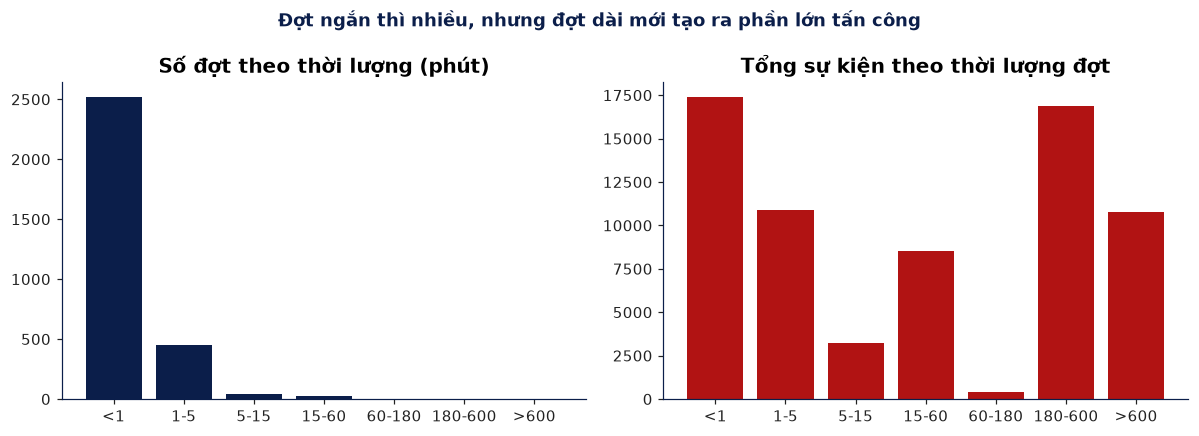

Đợt dài >60 phút: 7 đợt (0.2%) nhưng tạo 41.2% sự kiện


In [18]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
bins = [0,1,5,15,60,180,600,10000]; lab = ['<1','1-5','5-15','15-60','60-180','180-600','>600']
c = pd.cut(ses.thoi_luong_phut, bins, labels=lab, include_lowest=True).value_counts().reindex(lab)
ax[0].bar(lab, c.values, color=BLUE); ax[0].set_title('Số đợt theo thời lượng (phút)')
s = ses.groupby(pd.cut(ses.thoi_luong_phut, bins, labels=lab, include_lowest=True), observed=False).so_su_kien.sum().reindex(lab)
ax[1].bar(lab, s.values, color=RED); ax[1].set_title('Tổng sự kiện theo thời lượng đợt')
fig.suptitle('Đợt ngắn thì nhiều, nhưng đợt dài mới tạo ra phần lớn tấn công', fontweight='bold', color=BLUE)
plt.tight_layout(); plt.savefig(CHARTS/'08_dot_tan_cong.png'); plt.show()
print(f"Đợt dài >60 phút: {(ses.thoi_luong_phut>60).sum()} đợt ({(ses.thoi_luong_phut>60).mean():.1%}) nhưng tạo {ses.loc[ses.thoi_luong_phut>60,'so_su_kien'].sum()/ses.so_su_kien.sum():.1%} sự kiện")

### 5.3 Bot hay người? (tốc độ tấn công)
Người gõ tay khó thử nhanh hơn vài giây/lần. Quy tắc kinh nghiệm (heuristic):
- **Bot tốc độ cao**: đợt ≥ 10 sự kiện và khoảng cách trung vị giữa 2 sự kiện ≤ 5 giây.
- **Bot chậm / rải rác**: đợt ≥ 10 sự kiện nhưng chậm hơn (né rate-limit).
- **Dò quét lẻ**: đợt < 10 sự kiện.

                      so_dot  so_ip  so_su_kien  gap_tv  ty_le_su_kien
hanh_vi                                                               
Bot chậm (>5s)            20     20       11571    13.0          0.170
Bot tốc độ cao (≤5s)     324    270       46187     1.0          0.678
Dò quét lẻ (<10)        2693   1676       10322     0.5          0.152
Tốc độ đỉnh của 1 đợt: 160.9 sự kiện/phút | trung vị bot tốc độ cao: 40.0 sự kiện/phút


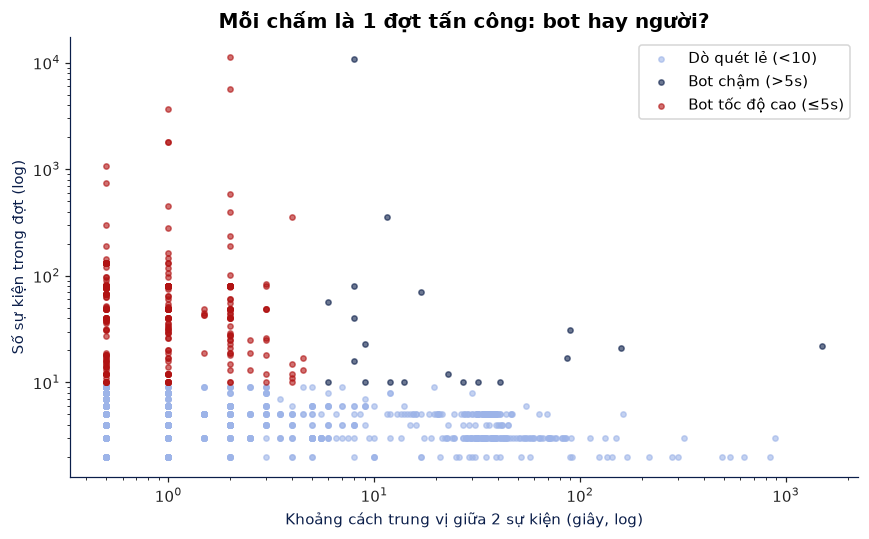

In [19]:
def loai(r):
    if r.so_su_kien < 10: return 'Dò quét lẻ (<10)'
    return 'Bot tốc độ cao (≤5s)' if r.gap_trung_vi_s <= 5 else 'Bot chậm (>5s)'
ses['hanh_vi'] = ses.apply(loai, axis=1)
hv = ses.groupby('hanh_vi').agg(so_dot=('ip','size'), so_ip=('ip','nunique'), so_su_kien=('so_su_kien','sum'), gap_tv=('gap_trung_vi_s','median'))
hv['ty_le_su_kien'] = (hv.so_su_kien/hv.so_su_kien.sum()).round(3); print(hv)
fast = ses[ses.hanh_vi.str.startswith('Bot tốc')]
print('Tốc độ đỉnh của 1 đợt:', round(ses.toc_do_moi_phut.max(),1), 'sự kiện/phút | trung vị bot tốc độ cao:', round(fast.toc_do_moi_phut.median(),1), 'sự kiện/phút')
fig, ax = plt.subplots(figsize=(8,5))
for k, col in zip(['Dò quét lẻ (<10)','Bot chậm (>5s)','Bot tốc độ cao (≤5s)'], ['#9DB4E8', BLUE, RED]):
    x = ses[ses.hanh_vi==k]; ax.scatter(x.gap_trung_vi_s.clip(lower=.5), x.so_su_kien, s=12, alpha=.6, color=col, label=k)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Khoảng cách trung vị giữa 2 sự kiện (giây, log)'); ax.set_ylabel('Số sự kiện trong đợt (log)')
ax.set_title('Mỗi chấm là 1 đợt tấn công: bot hay người?'); ax.legend(); plt.tight_layout(); plt.savefig(CHARTS/'09_bot_hay_nguoi.png'); plt.show()

### 5.4 Độ "lì" của IP: hoạt động bao nhiêu ngày, có quay lại không?

IP chỉ xuất hiện 1 ngày: 72.7% | IP quay lại ≥2 ngày: 504 | ≥5 ngày: 26
IP lì nhất: 112.101.64.87 - 9 ngày
IP quay lại chiếm 42.3% sự kiện


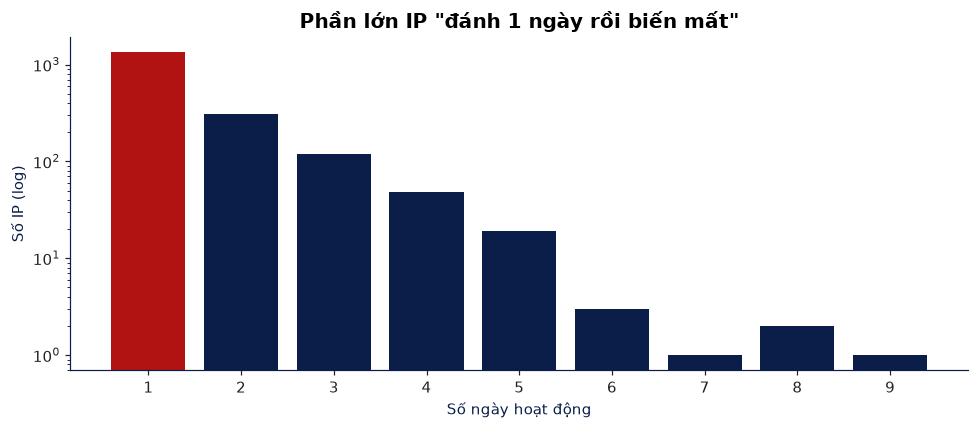

,lan_dau,lan_cuoi,so_ngay,so_su_kien,so_dot,khoang_ngay
ip,,,,,,
112.101.64.87,2000-12-04 21:49:33,2000-12-24 10:27:33,9,17,13,19
222.186.197.76,2000-12-10 05:50:19,2000-12-29 16:10:12,8,81,13,19
120.198.156.138,2000-12-24 21:47:23,2000-12-31 21:12:11,8,185,93,6
222.161.209.92,2000-12-11 14:56:47,2000-12-31 01:33:14,7,1493,10,19
122.225.109.114,2000-12-02 11:25:36,2000-12-25 06:51:32,6,35,6,22
91.135.226.34,2000-12-10 18:19:17,2000-12-29 11:34:23,6,400,8,18
124.74.77.178,2000-12-09 03:39:33,2000-12-28 09:06:57,6,23,7,19
218.2.0.120,2000-12-08 09:29:00,2000-12-30 06:42:13,5,14,5,21
221.231.143.4,2000-12-09 22:43:01,2000-12-23 08:22:00,5,63,9,13


In [20]:
ipd = att.groupby('ip').agg(lan_dau=('ts','min'), lan_cuoi=('ts','max'), so_ngay=('ngay','nunique'), so_su_kien=('ts','size'), so_dot=('session_id','nunique'))
ipd['khoang_ngay'] = (ipd.lan_cuoi - ipd.lan_dau).dt.days
vc = ipd.so_ngay.value_counts().sort_index()
print(f"IP chỉ xuất hiện 1 ngày: {(ipd.so_ngay==1).mean():.1%} | IP quay lại ≥2 ngày: {(ipd.so_ngay>=2).sum()} | ≥5 ngày: {(ipd.so_ngay>=5).sum()}")
print('IP lì nhất:', ipd.so_ngay.idxmax(), '-', ipd.so_ngay.max(), 'ngày')
ret = ipd[ipd.so_ngay>=2]; print(f"IP quay lại chiếm {ret.so_su_kien.sum()/ipd.so_su_kien.sum():.1%} sự kiện")
fig, ax = plt.subplots(figsize=(9,4)); ax.bar(vc.index.astype(str), vc.values, color=[RED if i==1 else BLUE for i in vc.index])
ax.set_yscale('log'); ax.set_xlabel('Số ngày hoạt động'); ax.set_ylabel('Số IP (log)'); ax.set_title('Phần lớn IP "đánh 1 ngày rồi biến mất"')
plt.tight_layout(); plt.savefig(CHARTS/'10_do_li_ip.png'); plt.show()
ipd.sort_values('so_ngay', ascending=False).head(10)

### 5.5 Gom theo dải mạng /24 và /16

In [21]:
att['subnet16'] = att.ip.str.split('.').str[:2].str.join('.') + '.0.0/16'
for col in ['subnet24','subnet16']:
    g = att.groupby(col).agg(so_ip=('ip','nunique'), so_su_kien=('ip','size')).sort_values('so_su_kien', ascending=False)
    print(col, '| số dải:', len(g), '| dải có ≥2 IP:', (g.so_ip>=2).sum(), '| dải nhiều IP nhất:', g.so_ip.idxmax(), g.so_ip.max(), 'IP')
    display(g.sort_values('so_ip', ascending=False).head(8))

subnet24 | số dải: 1435 | dải có ≥2 IP: 132 | dải nhiều IP nhất: 122.225.109.0/24 48 IP


,so_ip,so_su_kien
subnet24,,
122.225.109.0/24,48,560
122.225.97.0/24,32,349
61.174.51.0/24,31,494
54.173.58.0/24,27,27
54.173.57.0/24,25,25
54.173.56.0/24,24,24
61.174.50.0/24,22,324
122.225.103.0/24,16,96


subnet16 | số dải: 1043 | dải có ≥2 IP: 194 | dải nhiều IP nhất: 122.225.0.0/16 96 IP


,so_ip,so_su_kien
subnet16,,
122.225.0.0/16,96,1005
54.173.0.0/16,92,92
87.106.0.0/16,79,1620
61.174.0.0/16,55,822
85.214.0.0/16,24,94
82.165.0.0/16,21,459
109.63.0.0/16,14,25
87.118.0.0/16,13,76


### 5.6 Phân loại username bị thử
Nhóm: **mặc định/quản trị** (admin, test, guest…), **dịch vụ/CSDL** (oracle, postgres, mysql, ftp…), **thiết bị IoT** (pi, ubnt, support…), **số**, **tên người** (còn lại, chỉ chữ cái), **khác**.

                      so_lan_thu  so_username  so_ip  ty_le
nhom_user                                                  
Mặc định/quản trị           4234           28    892  0.346
Tên người/khác (chữ)        3813          316    646  0.311
Dịch vụ/CSDL                2303           37    488  0.188
Thiết bị IoT                1201            9    421  0.098
Ký tự hỗn hợp                671          149    301  0.055
Số                            18            2      7  0.001
Rỗng                          10            1      5  0.001
Mặc định/quản trị → admin, test, guest, default, user, info, web, Test
Tên người/khác (chữ) → debug, log, PlcmSpIp, karaf, arbab, xbian, dreamer, agata
Dịch vụ/CSDL → oracle, ftp, ftpuser, nagios, zabbix, apache, postgres, tomcat
Thiết bị IoT → vyatta, pi, xbmc, ubnt, support, ftp1, user2, cisco
Ký tự hỗn hợp → D-Link, zxin10, admin , apache2, r00t, oi-dev, exclusive_table, tech5i
Số → 123, 123456
Rỗng → nan


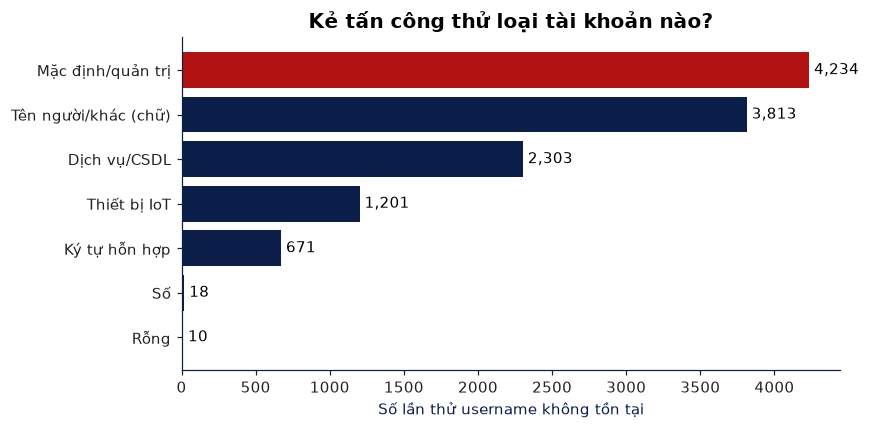

In [22]:
ADMIN = {'admin','administrator','test','test1','test2','tester','guest','user','user1','demo','root1','toor','default','master','manager','sysadmin','webadmin','admins','adm','system','info','operator','temp','tmp','server','backup','office','sales','web','www','student'}
SERVICE = {'oracle','postgres','mysql','ftp','ftpuser','git','nagios','tomcat','apache','hadoop','jenkins','www-data','ubuntu','deploy','svn','teamspeak','ts3','minecraft','redis','mongodb','zabbix','vagrant','ansible','docker','elasticsearch','postfix','squid','bin','daemon','nobody','mail','news','uucp','proxy','backup','list','irc','gnats','sshd','ftpadmin','oracle1','db2inst1','sybase','informix','jboss','weblogic','wildfly','nginx','httpd','cvs','postgresql','mythtv','asterisk','spark','hdfs','hive','kafka','solr','ts','bitnami','centos','ec2-user','debian','fedora','vnc','samba','cacti','plex','steam','csgo','teamspeak3','ftp_user','sinusbot','odoo','openerp','zimbra','www1','svnuser','gitlab','www2','mcserver','glassfish','webmaster','wp','wordpress','cpanel','vmail','postmaster','dovecot','exim','qmail','amanda'}
IOT = {'pi','ubnt','support','raspberry','admin1','cisco','ubuntu1','osmc','alarm','vyatta','service','supervisor','telnet','enable','monitor','camera','dvr','default','ftp1','router','pos','kodi','xbmc','openhab','usuario','user2','technician','mother'}
def ucat(u):
    u = str(u).lower()
    if u in ('', 'none', 'nan'): return 'Rỗng'
    if u in ADMIN: return 'Mặc định/quản trị'
    if u in SERVICE: return 'Dịch vụ/CSDL'
    if u in IOT: return 'Thiết bị IoT'
    if u.isdigit(): return 'Số'
    if u.isalpha(): return 'Tên người/khác (chữ)'
    return 'Ký tự hỗn hợp'
inv = att[att.event_type=='invalid_user'].copy(); inv['nhom_user'] = inv.username.map(ucat)
uc = inv.groupby('nhom_user').agg(so_lan_thu=('ip','size'), so_username=('username','nunique'), so_ip=('ip','nunique')).sort_values('so_lan_thu', ascending=False)
uc['ty_le'] = (uc.so_lan_thu/uc.so_lan_thu.sum()).round(3); print(uc)
for k in uc.index: print(k, '→', ', '.join(inv[inv.nhom_user==k].username.value_counts().head(8).index))
t = uc.sort_values('so_lan_thu'); fig, ax = plt.subplots(figsize=(8,4))
ax.barh(t.index, t.so_lan_thu, color=[RED if i==len(t)-1 else BLUE for i in range(len(t))])
for y,v in enumerate(t.so_lan_thu): ax.text(v, y, f' {v:,}', va='center')
ax.set_title('Kẻ tấn công thử loại tài khoản nào?'); ax.set_xlabel('Số lần thử username không tồn tại')
plt.tight_layout(); plt.savefig(CHARTS/'11_nhom_username.png'); plt.show()

### 5.7 Lý do ngắt kết nối & dấu vết công cụ tấn công
Dòng `Received disconnect from IP: <mã>: <lý do>` để lộ **thư viện/công cụ** mà bot dùng (ví dụ `com.jcraft.jsch` là thư viện SSH Java).

In [23]:
dis = att[att.event_type=='disconnect_preauth'].msg.str.extract(r'from \S+?:? (?P<ma>\d+): (?P<ly_do>.*?) ?\[preauth\]')
dr = dis.groupby(['ma','ly_do']).size().sort_values(ascending=False).rename('so_lan').reset_index(); print(dr.head(10))
jsch = att[att.msg.str.contains('jsch', case=False)]; print('Dòng có dấu vết JSch (Java):', len(jsch), '| từ', jsch.ip.nunique(), 'IP')
other = df[df.event_type=='other'].msg.str.replace(r'\d+\.\d+\.\d+\.\d+','IP',regex=True).str.replace(r'port \d+','port P',regex=True)
print('Các dòng "other" phổ biến:'); print(other.str.replace(r'for \S+ \[IP\]','for HOST [IP]',regex=True).str.replace(r'maps to \S+','maps to HOST',regex=True).value_counts().head(8))
rev = att[att.event_type=='reverse_mapping_failed']; print('Reverse DNS sai ("POSSIBLE BREAK-IN ATTEMPT"):', len(rev), 'dòng,', rev.ip.nunique(), 'IP')

   ma                                            ly_do  so_lan
0  11                                          Bye Bye   46601
1   3         com.jcraft.jsch.JSchException: Auth fail     157
2  11                                               ok      32
3  11                                                       12
4  11    No supported authentication methods available       7
5   3  java.net.SocketTimeoutException: Read timed out       1
Dòng có dấu vết JSch (Java): 157 | từ 11 IP
Các dòng "other" phổ biến:
msg
Address IP maps to HOST but this does not map back to the address - POSSIBLE BREAK-IN ATTEMPT!    725
Corrupted MAC on input. [preauth]                                                                  35
Bad protocol version identification 'GET / HTTP/1.0' from IP                                        9
Could not write ident string to IP                                                                  6
Could not write ident string to UNKNOWN                                     

### 5.8 Root vs. user không tồn tại theo thời gian
Bot có 2 chiến thuật: **đoán mật khẩu root** (bị chặn bởi "Too many authentication failures for root") và **đoán tên tài khoản** (invalid user).

Dòng root: 2575 | suy ra được IP: 52 | số IP tấn công root: 1
Top IP tấn công root:
ip_suy_ra
177.43.213.35    52
Name: count, dtype: int64


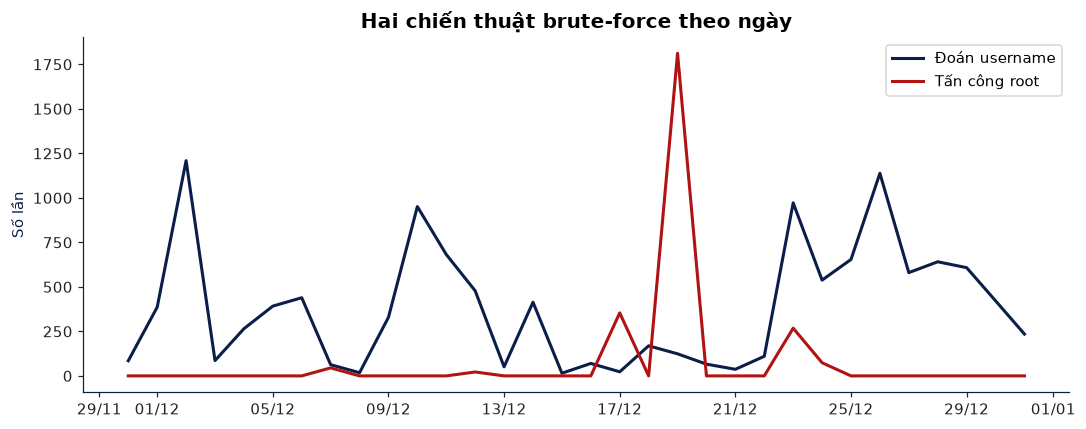

IP chỉ tấn công root: 1 | chỉ đoán username: 1260 | làm cả hai: 0
Số ngày có tấn công root: 6 / 32 | có đoán username: 32


In [24]:
# Dòng 'Too many authentication failures for root' KHÔNG ghi IP -> suy ra IP từ dòng khác cùng tiến trình sshd (cùng pid, cách ≤ 10 phút)
sshd = df[df.program=='sshd'].sort_values('ts').copy()
pid_ip = sshd.dropna(subset=['ip']).groupby('pid').agg(ip_pid=('ip','first'), ts_pid=('ts','first'))
sshd = sshd.join(pid_ip, on='pid')
ok = (sshd.ts - sshd.ts_pid).abs() <= pd.Timedelta(minutes=10)
sshd['ip_suy_ra'] = sshd.ip.fillna(sshd.ip_pid.where(ok))
rv = sshd[sshd.event_type.isin(['too_many_auth_failures','invalid_user'])].copy(); rv['ngay'] = rv.ts.dt.normalize()
rv['chien_thuat'] = rv.event_type.map({'too_many_auth_failures':'Tấn công root','invalid_user':'Đoán username'})
r = rv[rv.chien_thuat=='Tấn công root']; print('Dòng root:', len(r), '| suy ra được IP:', r.ip_suy_ra.notna().sum(), '| số IP tấn công root:', r.ip_suy_ra.nunique())
print('Top IP tấn công root:'); print(r.ip_suy_ra.value_counts().head(5))
rvd = rv.pivot_table(index='ngay', columns='chien_thuat', values='ts', aggfunc='size', fill_value=0)
fig, ax = plt.subplots(figsize=(10,4)); ax.plot(rvd.index, rvd['Đoán username'], color=BLUE, lw=2, label='Đoán username')
ax.plot(rvd.index, rvd['Tấn công root'], color=RED, lw=2, label='Tấn công root'); ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m')); ax.set_title('Hai chiến thuật brute-force theo ngày'); ax.set_ylabel('Số lần')
plt.tight_layout(); plt.savefig(CHARTS/'12_root_vs_username.png'); plt.show()
A, B = set(r.ip_suy_ra.dropna()), set(rv[rv.chien_thuat=='Đoán username'].ip_suy_ra.dropna())
print('IP chỉ tấn công root:', len(A-B), '| chỉ đoán username:', len(B-A), '| làm cả hai:', len(A&B))
print('Số ngày có tấn công root:', (rvd['Tấn công root']>0).sum(), '/', len(rvd), '| có đoán username:', (rvd['Đoán username']>0).sum())
root_ip = r.ip_suy_ra.value_counts()

### 5.9 Đường cong Pareto
Sắp IP từ mạnh đến yếu, cộng dồn % sự kiện: bao nhiêu % IP tạo ra 80% tấn công?

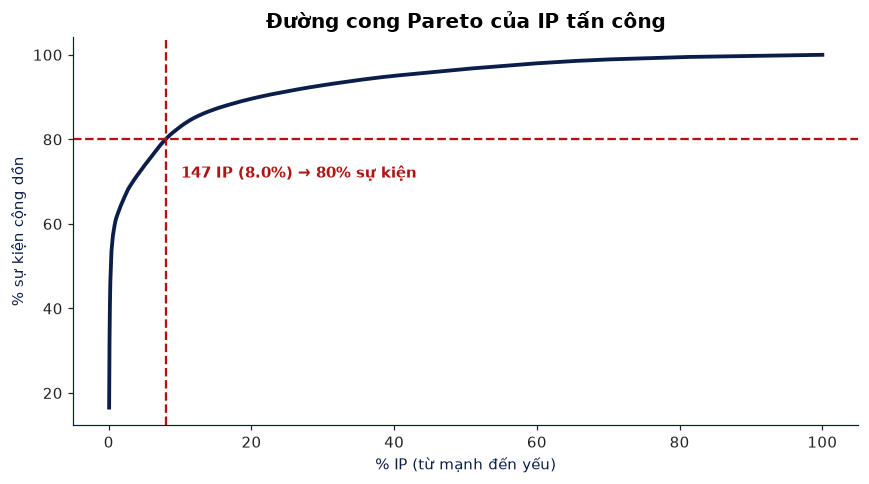

147 IP = 8.0% số IP tạo 80% sự kiện | top 1% IP (18) tạo 60.9%


In [25]:
p = ipd.so_su_kien.sort_values(ascending=False).cumsum()/ipd.so_su_kien.sum()
x = np.arange(1, len(p)+1)/len(p)
n80 = int((p<0.8).sum())+1
fig, ax = plt.subplots(figsize=(8,4.5)); ax.plot(x*100, p.values*100, color=BLUE, lw=2.5)
ax.axhline(80, color=RED, ls='--'); ax.axvline(n80/len(p)*100, color=RED, ls='--')
ax.annotate(f'{n80} IP ({n80/len(p):.1%}) → 80% sự kiện', (n80/len(p)*100, 80), xytext=(10,-25), textcoords='offset points', color=RED, fontweight='bold')
ax.set_xlabel('% IP (từ mạnh đến yếu)'); ax.set_ylabel('% sự kiện cộng dồn'); ax.set_title('Đường cong Pareto của IP tấn công')
plt.tight_layout(); plt.savefig(CHARTS/'13_pareto.png'); plt.show()
print(f'{n80} IP = {n80/len(p):.1%} số IP tạo 80% sự kiện | top 1% IP ({int(len(p)*.01)}) tạo {p.iloc[int(len(p)*.01)-1]:.1%}')

### 5.10 Địa lý & nhà mạng (ASN)
> ⚠️ **Lưu ý quan trọng:** vị trí lấy từ cơ sở dữ liệu offline **DB-IP Lite bản 2026-10** (CC BY 4.0, https://db-ip.com) – tức là vị trí **hiện tại** của IP, không phải lúc tấn công. IP có thể đã đổi chủ, và kẻ tấn công thường đi qua máy bị chiếm/VPS thuê, nên quốc gia ≠ quốc tịch kẻ tấn công. File kết quả: `data/ip_geo.csv` (tạo bởi `geo_lookup.py`).

In [26]:
geo = pd.read_csv('data/ip_geo.csv', keep_default_na=False, na_values=[''])
ipd = ipd.join(geo.set_index('ip'))
ctry = ipd.groupby('country_code').agg(so_ip=('so_su_kien','size'), so_su_kien=('so_su_kien','sum')).sort_values('so_su_kien', ascending=False)
ctry['ty_le_su_kien'] = (ctry.so_su_kien/ctry.so_su_kien.sum()).round(3); ctry['ty_le_ip'] = (ctry.so_ip/ctry.so_ip.sum()).round(3)
print('Số quốc gia:', len(ctry)); display(ctry.head(12))
print('Top quốc gia theo số IP:', ', '.join(f'{k} {v}' for k,v in ctry.so_ip.nlargest(5).items()))
asn = ipd.groupby(['asn','as_org']).agg(so_ip=('so_su_kien','size'), so_su_kien=('so_su_kien','sum')).sort_values('so_su_kien', ascending=False)
print('Số ASN:', len(asn)); display(asn.head(10)); display(asn.sort_values('so_ip', ascending=False).head(8))
print('IP Việt Nam:', int(ctry.so_ip.get('VN',0)), '| sự kiện:', int(ctry.so_su_kien.get('VN',0)))

Số quốc gia: 80


,so_ip,so_su_kien,ty_le_su_kien,ty_le_ip
country_code,,,,
JP,59,22650,0.333,0.032
CN,423,15467,0.227,0.230
US,371,6448,0.095,0.201
ES,33,3987,0.059,0.018
GB,66,3423,0.050,0.036
DE,147,2124,0.031,0.080
FR,120,1913,0.028,0.065
CA,27,1860,0.027,0.015
KR,51,1123,0.016,0.028


Top quốc gia theo số IP: CN 423, US 371, DE 147, FR 120, RU 71
Số ASN: 539


,,so_ip,so_su_kien
asn,as_org,,
2514.0,"NTT PC Communications, Inc.",7,11301
4713.0,NTT Communications Corporation,9,10822
4837.0,CHINA UNICOM China169 Backbone,39,7854
4134.0,Chinanet,237,4083
12430.0,VODAFONE ESPANA S.A.U.,1,3676
8560.0,IONOS SE,126,2514
20860.0,IOMART CLOUD SERVICES LIMITED,19,2287
26347.0,"New Dream Network, LLC",1,1804
3786.0,LG DACOM Corporation,12,679


,,so_ip,so_su_kien
asn,as_org,,
4134.0,Chinanet,237,4083
8560.0,IONOS SE,126,2514
14618.0,"Amazon.com, Inc.",104,258
4837.0,CHINA UNICOM China169 Backbone,39,7854
16509.0,"Amazon.com, Inc.",34,560
6724.0,Strato AG,33,129
7922.0,"Comcast Cable Communications, LLC",25,147
4538.0,China Education and Research Network Center,22,479


IP Việt Nam:

 16 | sự kiện: 703


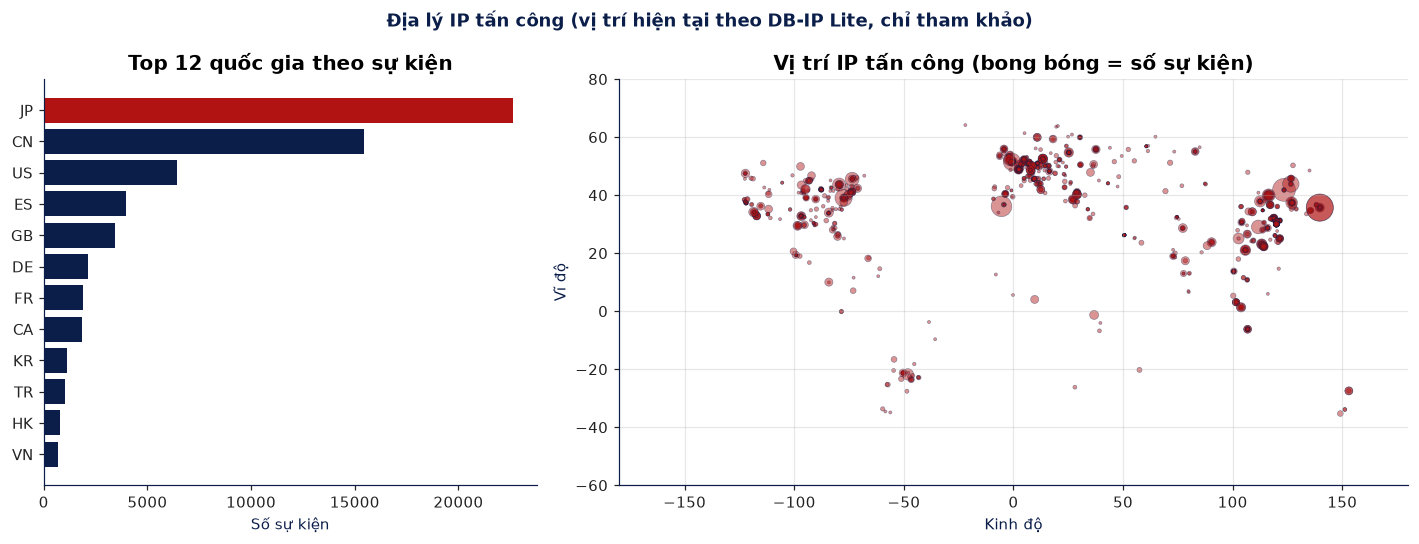

In [27]:
fig, ax = plt.subplots(1,2, figsize=(13,5), gridspec_kw={'width_ratios':[1,1.6]})
t = ctry.head(12).sort_values('so_su_kien'); ax[0].barh(t.index, t.so_su_kien, color=BLUE); ax[0].barh(t.index[-1:], t.so_su_kien[-1:], color=RED)
ax[0].set_title('Top 12 quốc gia theo sự kiện'); ax[0].set_xlabel('Số sự kiện')
m = ipd.dropna(subset=['lat'])
ax[1].scatter(m.lon, m.lat, s=np.clip(np.sqrt(m.so_su_kien)*3, 4, 400), color=RED, alpha=.45, edgecolor=BLUE, lw=.4)
ax[1].set_xlim(-180,180); ax[1].set_ylim(-60,80); ax[1].set_xlabel('Kinh độ'); ax[1].set_ylabel('Vĩ độ')
ax[1].set_title('Vị trí IP tấn công (bong bóng = số sự kiện)'); ax[1].grid(alpha=.3)
fig.suptitle('Địa lý IP tấn công (vị trí hiện tại theo DB-IP Lite, chỉ tham khảo)', fontweight='bold', color=BLUE)
plt.tight_layout(); plt.savefig(CHARTS/'14_dia_ly.png'); plt.show()

## 6. Xuất dữ liệu cho Power BI (star schema)
Ghi 4 bảng CSV (UTF-8 có BOM để Power BI/Excel đọc đúng tiếng Việt) vào thư mục `powerbi/`:
- `fact_su_kien.csv` – mỗi dòng 1 sự kiện SSH (kể cả dòng không có IP)
- `dim_ip.csv` – mỗi IP: quốc gia, thành phố, toạ độ, ASN, tổng số, phân loại
- `dim_ngay.csv` – lịch ngày
- `dim_username.csv` – mỗi username + nhóm
- thêm `fact_dot_tan_cong.csv` – mỗi đợt tấn công (session)

In [28]:
PB = Path('powerbi'); PB.mkdir(exist_ok=True)
fact = df[df.program=='sshd'].copy().merge(att[['session_id']], left_index=True, right_index=True, how='left')
fact['ip'] = fact.ip.fillna(sshd.ip_suy_ra.reindex(fact.index))  # điền IP suy ra từ pid cho dòng root
fact['event_id'] = fact.index + 1
fact['timestamp'] = fact.ts.dt.strftime('%Y-%m-%d %H:%M:%S'); fact['ngay'] = fact.ts.dt.strftime('%Y-%m-%d'); fact['gio'] = fact.ts.dt.hour
fact['username'] = fact.username.where(fact.event_type.isin(['invalid_user','too_many_auth_failures']))
fact[['event_id','timestamp','ngay','gio','ip','username','event_type','session_id']].to_csv(PB/'fact_su_kien.csv', index=False, encoding='utf-8-sig')
def ip_cat(r):
    if r.so_su_kien >= 1000: return 'Brute-force nặng (≥1000)'
    if r.so_su_kien >= 100: return 'Brute-force (100-999)'
    if r.so_su_kien >= 10: return 'Thử nghiệm (10-99)'
    return 'Dò quét lẻ (<10)'
dim_ip = ipd.copy(); dim_ip['asn'] = dim_ip.asn.astype('Int64'); dim_ip['phan_loai'] = dim_ip.apply(ip_cat, axis=1)
dim_ip['so_lan_thu_user'] = att[att.event_type=='invalid_user'].groupby('ip').size().reindex(dim_ip.index, fill_value=0)
dim_ip['so_lan_root'] = root_ip.reindex(dim_ip.index, fill_value=0)
dim_ip['subnet24'] = att.groupby('ip').subnet24.first()
dim_ip['hanh_vi_chinh'] = ses.sort_values('so_su_kien').groupby('ip').hanh_vi.last()
dim_ip['lan_dau'] = dim_ip.lan_dau.dt.strftime('%Y-%m-%d %H:%M:%S'); dim_ip['lan_cuoi'] = dim_ip.lan_cuoi.dt.strftime('%Y-%m-%d %H:%M:%S')
dim_ip = dim_ip.reset_index().rename(columns={'index':'ip'})
dim_ip[['ip','country_code','continent','region','city','lat','lon','asn','as_org','subnet24','so_su_kien','so_lan_thu_user','so_lan_root','so_dot','so_ngay','lan_dau','lan_cuoi','phan_loai','hanh_vi_chinh','geo_source']].to_csv(PB/'dim_ip.csv', index=False, encoding='utf-8-sig')
d = pd.DataFrame({'ngay': pd.date_range(fact.ts.min().normalize(), fact.ts.max().normalize())})
d['ngay_thang'] = d.ngay.dt.strftime('%d/%m'); d['thang'] = d.ngay.dt.month; d['ten_thang'] = 'Tháng ' + d.thang.astype(str)
d['ngay_trong_thang'] = d.ngay.dt.day; d['tuan'] = ((d.ngay - d.ngay.min()).dt.days // 7 + 1).map(lambda w: f'Tuần {w}')
d['ngay'] = d.ngay.dt.strftime('%Y-%m-%d'); d.to_csv(PB/'dim_ngay.csv', index=False, encoding='utf-8-sig')
du = fact.dropna(subset=['username']).groupby('username').agg(so_lan_thu=('event_id','size'), so_ip=('ip','nunique')).reset_index()
du['nhom_user'] = du.username.map(lambda u: 'Root (tồn tại)' if u=='root' else ucat(u)); du['do_dai'] = du.username.str.len()
du.to_csv(PB/'dim_username.csv', index=False, encoding='utf-8-sig')
s2 = ses.reset_index(); s2['bat_dau'] = s2.bat_dau.dt.strftime('%Y-%m-%d %H:%M:%S'); s2['ket_thuc'] = s2.ket_thuc.dt.strftime('%Y-%m-%d %H:%M:%S'); s2['ngay'] = s2.bat_dau.str[:10]
s2.round(2).to_csv(PB/'fact_dot_tan_cong.csv', index=False, encoding='utf-8-sig')
for f in sorted(PB.glob('*.csv')): print(f.name, len(pd.read_csv(f, encoding='utf-8-sig')), 'dòng')

dim_ip.csv 1843 dòng
dim_ngay.csv 32 dòng
dim_username.csv 543 dòng
fact_dot_tan_cong.csv 3037 dòng
fact_su_kien.csv 85246 dòng


## 7. Kết luận (v1)
- File log có **86.839 dòng** (30/11 – 31/12), parse được 100% bằng regex; **85.246 dòng** là của `sshd` – gần như toàn bộ log là các lần dò quét/đăng nhập SSH từ Internet.
- Có **1.843 IP** khác nhau tấn công, nhưng **top 10 IP chiếm 56,5%** sự kiện có IP. IP mạnh nhất `61.197.203.243` tạo **11.261 sự kiện chỉ trong khoảng 5 giờ** ngày 06/12; `220.99.93.50` tạo 10.752 sự kiện trong 2 ngày. Hầu hết IP top chỉ hoạt động 1 ngày → kiểu bot "đánh nhanh rồi rút".
- Gom theo dải /24 không làm thay đổi bảng xếp hạng (mỗi dải gần như chỉ 1 IP) → tấn công đến từ các máy đơn lẻ rải rác, không tập trung một mạng.
- Ngày cao điểm **02/12 với 17.548 sự kiện**, gấp ~9,5 lần trung vị **1.848 sự kiện/ngày** → tấn công đến thành từng đợt bùng nổ.
- Kẻ tấn công thử **12.250 lần với 542 username không tồn tại**; đứng đầu là `admin` (1.912 lần, 784 IP), `test`, `guest`, `oracle`, `ftp` và các tài khoản mặc định thiết bị như `D-Link`, `pi`, `PlcmSpIp`, `vyatta`. Riêng `root` bị ngắt phiên **2.575 lần** do "Too many authentication failures".
- Độ lớn brute-force: **82,1% IP thử ≤ 10 lần** nhưng chỉ đóng góp 22,5% số lần thử; **221 IP (17,5%) thử > 10 lần lại tạo 77,5%** số lần thử.
- Server không có dòng `Failed password`/`Accepted` nào trong khoảng này → nhiều khả năng đã chỉ cho đăng nhập bằng key; không thấy dấu hiệu đăng nhập thành công của kẻ tấn công trong log.

## 6. Khuyến nghị phòng thủ
1. **Tắt đăng nhập bằng mật khẩu và tắt root login**: `PasswordAuthentication no`, `PermitRootLogin no` trong `sshd_config`, chỉ dùng SSH key.
2. **fail2ban / sshguard**: chặn IP sau ~5 lần thất bại trong 10 phút – sẽ chặn ngay các IP "bùng nổ" như top 10.
3. **Rate limit kết nối** bằng firewall (`ufw limit ssh` hoặc `iptables -m recent`) và `MaxStartups`, `MaxAuthTries 3`.
4. **Giới hạn nguồn truy cập**: AWS Security Group chỉ mở cổng 22 cho IP tin cậy, hoặc dùng VPN/bastion; có thể đổi cổng để giảm nhiễu (không thay thế bảo mật thật).
5. **Không dùng tên tài khoản phổ biến** (`admin`, `test`, `pi`...), đổi mật khẩu mặc định của thiết bị; dùng `AllowUsers` để chỉ định user được SSH.
6. **Giám sát & cảnh báo**: đẩy auth.log về SIEM, cảnh báo khi số sự kiện/giờ vượt ngưỡng hoặc có `Accepted` từ IP lạ.

## 7. Hướng mở rộng
Tra quốc gia/ASN bằng GeoIP (MaxMind GeoLite2), dựng dashboard (Power BI/Streamlit), so sánh với log honeypot có ghi mật khẩu.

*Dữ liệu: SecRepo.com – Mike Sconzo, CC BY 4.0.*


## 8. 12 insight chính (v2) & khuyến nghị phòng thủ
*(Mọi con số dưới đây lấy trực tiếp từ output các ô code ở mục 5.)*

1. **Pareto cực đoan:** chỉ **147 IP (8,0%)** tạo ra **80%** sự kiện; **top 1% (18 IP)** tạo **60,9%** → chặn đúng vài chục IP là cắt được phần lớn tấn công.
2. **Gần như toàn bộ là bot:** các đợt "bot tốc độ cao" (khoảng cách trung vị ≤ 5 giây) chỉ là **324/3.037 đợt** từ **270 IP** nhưng tạo **67,8%** sự kiện, trung vị **1 giây/sự kiện ≈ 40 sự kiện/phút**; đợt nhanh nhất đạt **160,9 sự kiện/phút** (`173.192.158.3`). Không người nào gõ tay được tốc độ này.
3. **Vài đợt dài gây hại nhiều nhất:** chỉ **7 đợt kéo dài > 60 phút (0,2%)** nhưng chiếm **41,2%** sự kiện; đợt dài nhất **21,6 giờ** (`220.99.93.50`, 10.752 sự kiện).
4. **"Gõ cửa rồi đi":** **18,7%** đợt chỉ có 1 sự kiện; 2.693 đợt dò quét lẻ (< 10 sự kiện) từ 1.676 IP chỉ tạo **15,2%** sự kiện → đây là tiếng ồn nền của Internet.
5. **Đa số IP dùng 1 lần, nhưng nhóm quay lại rất nguy hiểm:** **72,7%** IP chỉ xuất hiện 1 ngày; **504 IP quay lại ≥ 2 ngày** tạo **42,3%** sự kiện; 26 IP hoạt động ≥ 5 ngày, lì nhất `112.101.64.87` (9 ngày) và `222.161.209.92` (7 ngày, 1.493 sự kiện) → chặn vĩnh viễn IP tái phạm.
6. **Tấn công gần như không ngừng:** **615/768 giờ (80%)** trong tháng có tấn công; nhưng **10 giờ nặng nhất chiếm 34,4%**, đỉnh **02/12 lúc 15h: 3.576 sự kiện/giờ** → cần cảnh báo theo ngưỡng/giờ chứ không chỉ theo ngày.
7. **Tấn công theo cụm dải mạng:** dải `122.225.0.0/16` có **96 IP** (riêng `122.225.109.0/24` 48 IP); 3 dải liền nhau `54.173.56–58.0/24` (Amazon) có 76 IP mà mỗi IP chỉ 1 sự kiện → máy quét chạy trên cloud, xoay vòng IP để né chặn theo IP.
8. **Số IP ≠ mức độ nguy hiểm theo quốc gia:** Nhật Bản chỉ **59 IP (3,2%)** nhưng tạo **33,3%** sự kiện (2 nhà mạng NTT); Trung Quốc **423 IP (23%)** tạo 22,7%; Mỹ **371 IP (20,1%)** chỉ 9,5%. Tổng **80 quốc gia, 539 ASN**; Việt Nam 16 IP / 703 sự kiện.
9. **Hạ tầng thường gặp:** Chinanet (237 IP), IONOS (126 IP), Amazon (104 + 34 IP) là các ASN có nhiều IP tấn công nhất → nhiều máy chủ hosting/cloud bị chiếm hoặc bị thuê để tấn công.
10. **Kẻ tấn công nhắm tài khoản mặc định:** nhóm mặc định/quản trị (`admin`, `test`, `guest`…) chiếm **34,6%** lần thử; dịch vụ/CSDL (`oracle`, `ftp`, `nagios`, `postgres`…) **18,8%**; thiết bị IoT (`pi`, `ubnt`, `vyatta`…) **9,8%** → không bao giờ để tài khoản mặc định có mật khẩu trên server mở SSH.
11. **Dấu vết công cụ:** **46.601** lần ngắt kết nối với thông điệp `Bye Bye` (chữ ký của script brute-force); **157** dòng lộ thư viện Java **JSch** từ 11 IP; 9 lần gửi `GET / HTTP/1.0` vào cổng SSH (máy quét web quét nhầm cổng); **5.226** dòng reverse-DNS không khớp từ 254 IP.
12. **Tấn công root đến theo đợt và giấu IP:** 2.575 lần bị ngắt "Too many authentication failures for root" chỉ rơi vào **6/32 ngày**, và log **không ghi IP** ở dòng này (chỉ suy ra được 52 dòng qua pid) → nên bật `LogLevel VERBOSE` để có đủ IP.

### Khuyến nghị phòng thủ (ưu tiên theo insight)
| # | Hành động | Dựa trên insight |
|---|---|---|
| 1 | `PasswordAuthentication no`, `PermitRootLogin no`, chỉ dùng SSH key | 10, 12 |
| 2 | fail2ban: cấm ≥ 5 lần sai/10 phút, **cấm tăng dần** cho IP tái phạm | 2, 5 |
| 3 | Rate-limit kết nối (`ufw limit 22/tcp`, `MaxStartups`, `MaxAuthTries 3`) | 2, 3 |
| 4 | Chặn theo dải /24 hoặc ASN khi nhiều IP cùng dải tấn công | 7, 9 |
| 5 | Chỉ cho phép IP tin cậy / VPN vào cổng 22, hoặc đổi cổng để giảm tiếng ồn | 4, 6 |
| 6 | `LogLevel VERBOSE` + gửi log về SIEM, cảnh báo khi > N sự kiện/giờ | 6, 12 |
| 7 | Xoá/khoá tài khoản mặc định (`pi`, `ubnt`, `oracle`, `test`…) trên mọi máy | 10 |


In [29]:
con.close()